# Prédiction des besoins de chauffage avec SVR + WSO

**BADDOU Halima & EL GOUDE Meriem— Master IAA**



## 1. Importer les bibliothèques



In [9]:
import io
import json
import time
import zipfile
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



## 2. Régler l'expérience

In [10]:
SEED = 42  # Fixer le hasard
POPULATION = 12  # Nombre de solutions candidates
ITERATIONS = 15  # Nombre de cycles de recherche de WSO
FOLDS = 3  # Nombre de parties utilisées en validation croisée
OUT = Path('resultats')  # Dossier des résultats produits par cette exécution.




### 3.Télécharger et charger les données

In [11]:
url = "https://archive.ics.uci.edu/static/public/242/energy+efficiency.zip"

with urllib.request.urlopen(url, timeout=60) as response:
    contenu = response.read()

archive = zipfile.ZipFile(io.BytesIO(contenu))

with archive.open("ENB2012_data.xlsx") as fichier:
    df = pd.read_excel(fichier)



### 4.Exporter les données en CSV

In [12]:
Path("data").mkdir(exist_ok=True)

df.to_csv("data/energy_efficiency.csv")

print("Données enregistrées dans data/energy_efficiency.csv")

Données enregistrées dans data/energy_efficiency.csv


### 5. Explorer les données et définir X et y

In [14]:
print("Dimensions :", df.shape)

display(df.head())
df.info()

print("\nValeurs manquantes :")
print(df.isna().sum())
display(df.describe())

features = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8"]
assert len(df) == 768
assert not df[features + ["Y1"]].isna().any().any()
X = df[features]
y = df["Y1"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions : (768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB

Valeurs manquantes :
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


Dimensions de X : (768, 8)
Dimensions de y : (768,)


## 6. Séparer les données **texte en gras**

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
cv = list(KFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(X_train))
numeric = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']
categorical = ['X6', 'X8']




## 7.Preparer la validation des données

In [16]:
def create_model(C=1.0, gamma='scale', epsilon=0.1):
    preparation = ColumnTransformer([
        ('num', StandardScaler(), numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ])
    return Pipeline([
        ('preparation', preparation),
        ('svr', SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon)),
    ])

def cv_rmse(model):
    negative_scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1
    )
    return float(-negative_scores.mean())

## 8. Définir le problème d'optimisation



In [17]:
lower = np.array([-1.0, -4.0, -3.0])
upper = np.array([3.0, 0.0, 0.0])

def decode(position):
    C, gamma, epsilon = 10.0 ** (lower + position * (upper - lower))
    return dict(C=float(C), gamma=float(gamma), epsilon=float(epsilon))

def objective(position):
    return cv_rmse(create_model(**decode(position)))



## 9. Implémenter WSO avec NumPy



In [18]:
def wso(objective, population=12, iterations=15, seed=42):
    rng = np.random.default_rng(seed)
    positions = rng.uniform(0, 1, (population, 3))
    velocities = np.zeros_like(positions)
    costs = np.array([objective(p) for p in positions])
    best_index = np.argmin(costs)
    best = positions[best_index].copy()
    best_cost = float(costs[best_index])
    history = [best_cost]
    tau = 4.125
    mu = 2 / abs(2 - tau - np.sqrt(tau**2 - 4*tau))
    for step in range(1, iterations + 1):
        decay = np.exp(-(4 * step / iterations)**2)
        p1 = 1.5 + decay
        p2 = 0.5 + decay
        movement = 1 / (6.25 + np.exp((iterations / 2 - step) / 100))
        school = abs(1 - np.exp(-0.0005 * step / iterations))
        peers = positions[rng.integers(0, population, population)]
        r1 = rng.random(positions.shape)
        r2 = rng.random(positions.shape)
        velocities = mu * (velocities + p1*r1*(best-positions) + p2*r2*(peers-positions))
        frequencies = rng.uniform(0.07, 0.75, (population, 1))
        candidates = positions + velocities / frequencies
        stay = rng.random(population) < movement
        candidates[stay] = positions[stay]
        candidates = np.clip(candidates, 0, 1)
        for i in range(population):
            if i < school * population:
                distance = abs(rng.random(3) * (best - candidates[i]))
                direction = np.where(rng.random(3) > 0.5, 1, -1)
                nearby = best + rng.random(3) * distance * direction
                divisor = 2 * np.maximum(rng.random(3), 1e-12)
                candidates[i] = np.clip((candidates[i] + nearby) / divisor, 0, 1)
            value = objective(candidates[i])
            if value < costs[i]:
                positions[i] = candidates[i]
                costs[i] = value
            if value < best_cost:
                best, best_cost = candidates[i].copy(), float(value)
        history.append(best_cost)
        print(f'Itération {step:02d}/{iterations} : RMSE CV = {best_cost:.4f}', flush=True)
    return best, best_cost, history



## 10. Entraîner les références et lancer WSO



In [19]:
baseline = create_model()
baseline_cv = cv_rmse(baseline)
start = time.perf_counter()
best_position, best_cv, history = wso(objective, POPULATION, ITERATIONS, SEED)
wso_seconds = time.perf_counter() - start
best_params = decode(best_position)
print('Meilleurs hyperparamètres :', best_params)
budget = POPULATION * (ITERATIONS + 1)
rng_random = np.random.default_rng(SEED + 1)
random_positions = rng_random.uniform(0, 1, (budget, 3))
start = time.perf_counter()
random_costs = np.array([objective(p) for p in random_positions])
random_seconds = time.perf_counter() - start
random_index = np.argmin(random_costs)
random_params = decode(random_positions[random_index])



Itération 01/15 : RMSE CV = 0.9683
Itération 02/15 : RMSE CV = 0.9683
Itération 03/15 : RMSE CV = 0.9683
Itération 04/15 : RMSE CV = 0.9683
Itération 05/15 : RMSE CV = 0.9683
Itération 06/15 : RMSE CV = 0.9683
Itération 07/15 : RMSE CV = 0.9683
Itération 08/15 : RMSE CV = 0.9683
Itération 09/15 : RMSE CV = 0.9683
Itération 10/15 : RMSE CV = 0.9683
Itération 11/15 : RMSE CV = 0.9683
Itération 12/15 : RMSE CV = 0.9683
Itération 13/15 : RMSE CV = 0.9683
Itération 14/15 : RMSE CV = 0.9401
Itération 15/15 : RMSE CV = 0.9401
Meilleurs hyperparamètres : {'C': 1000.0, 'gamma': 0.0683623293740392, 'epsilon': 0.006219548396136771}


## 11. Évaluer une fois les configurations finales sur le test



In [20]:
models = {
    'SVR initial': baseline,
    'SVR + WSO': create_model(**best_params),
    'SVR + recherche aleatoire': create_model(**random_params),
}
cv_values = [baseline_cv, best_cv, float(random_costs[random_index])]
rows = []
predictions = pd.DataFrame({'index_original': X_test.index, 'valeur_reelle': y_test.to_numpy()})
for (name, model), cv_value in zip(models.items(), cv_values):
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    predictions[name] = prediction
    rows.append({
        'Modele': name, 'RMSE_CV': cv_value,
        'RMSE_test': float(np.sqrt(mean_squared_error(y_test, prediction))),
        'MAE_test': float(mean_absolute_error(y_test, prediction)),
        'R2_test': float(r2_score(y_test, prediction)),
    })
results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv(OUT / 'comparaison.csv', index=False)
predictions.to_csv(OUT / 'predictions_test.csv', index=False)
pd.DataFrame({'iteration': range(len(history)), 'RMSE_CV': history}).to_csv(OUT/'convergence.csv', index=False)
metadata = {
    'seed': SEED, 'population': POPULATION, 'iterations': ITERATIONS, 'folds': FOLDS,
    'train_size': len(X_train), 'test_size': len(X_test), 'calls_per_search': budget,
    'best_params_wso': best_params, 'best_params_random': random_params,
    'wso_seconds': wso_seconds, 'random_seconds': random_seconds,
    'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
    'train_indices': X_train.index.tolist(), 'test_indices': X_test.index.tolist(),
}
(OUT/'experience.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')  # Enregistrer.



                   Modele  RMSE_CV  RMSE_test  MAE_test  R2_test
              SVR initial 2.706755   2.663562  1.657852 0.931935
                SVR + WSO 0.940060   0.511822  0.368634 0.997487
SVR + recherche aleatoire 0.981786   0.705743  0.508007 0.995222


7370

## 12. Visualiser les résultats


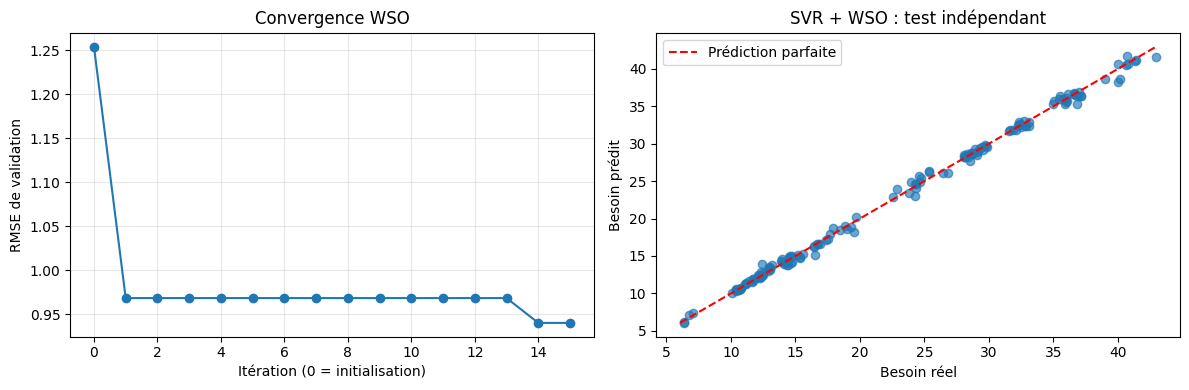

Terminé : les fichiers sont dans le dossier resultats.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(len(history)), history, marker='o')
axes[0].set(xlabel='Itération (0 = initialisation)', ylabel='RMSE de validation', title='Convergence WSO')
axes[0].grid(alpha=0.3)
axes[1].scatter(y_test, predictions['SVR + WSO'], alpha=0.65)
limits = [min(y_test.min(), predictions['SVR + WSO'].min()), max(y_test.max(), predictions['SVR + WSO'].max())]
axes[1].plot(limits, limits, 'r--', label='Prédiction parfaite')
axes[1].set(xlabel='Besoin réel', ylabel='Besoin prédit', title='SVR + WSO : test indépendant')
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT/'graphiques.png', dpi=180)
plt.show()
print('Terminé : les fichiers sont dans le dossier resultats.')


## Télécharger les résultats



In [22]:
import shutil
shutil.make_archive('resultats_WSO_SVR', 'zip', 'resultats')
from google.colab import files
files.download('resultats_WSO_SVR.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>